# Step 1: Setup and Data Loading

In [8]:
# General data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Scikit-learn for modeling
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Load the dataset
from sklearn.datasets import load_breast_cancer

# Load data
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target)

print("Dataset Shape:")
print(f"Features (X): {X.shape}")
print(f"Target (y): {y.shape}\n")

print("First 5 rows of features:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Dataset Shape:
Features (X): (569, 30)
Target (y): (569,)

First 5 rows of features:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean

# Step 2: Data Preprocessing and Splitting

In [9]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 455 samples
Test set size: 114 samples


# Step 3: Initial Model Training (Baseline Performance)

In [10]:
# Define models to train
models = {
    "Logistic Regression": LogisticRegression(max_iter=10000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Classifier": SVC(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Store results
baseline_results = []

# Loop through models, create a pipeline, train, and evaluate
for name, model in models.items():
    # Create a pipeline with a scaler and the model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])
    
    # Train the model
    pipeline.fit(X_train, y_train)
    
    # Make predictions
    y_pred = pipeline.predict(X_test)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # Store results
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })
    
    print(f"--- {name} ---")
    print(classification_report(y_test, y_pred))

# Display baseline results in a DataFrame
baseline_df = pd.DataFrame(baseline_results)
print("\n--- Baseline Model Performance Summary ---")
print(baseline_df)

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

--- K-Nearest Neighbors ---
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

--- Support Vector Classifier ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98     

# Step 4: Hyperparameter Tuning with GridSearchCV


--- Running GridSearchCV for Random Forest ---
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Best Parameters found by GridSearchCV: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 100}
Best F1-Score from GridSearchCV: 0.9668

--- Performance of GridSearchCV-tuned Model on Test Set ---
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


--- Confusion Matrix for Tuned Random Forest ---


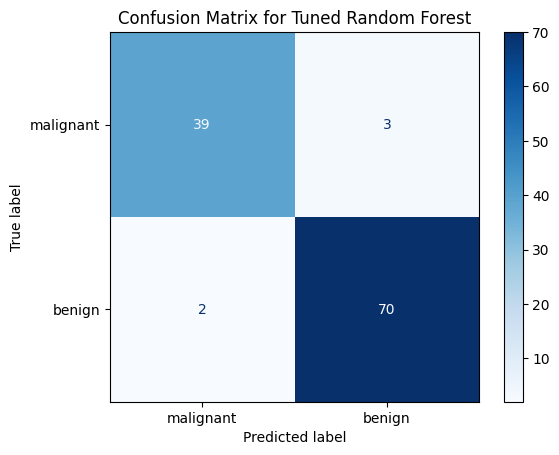


--- Top 10 Feature Importances ---


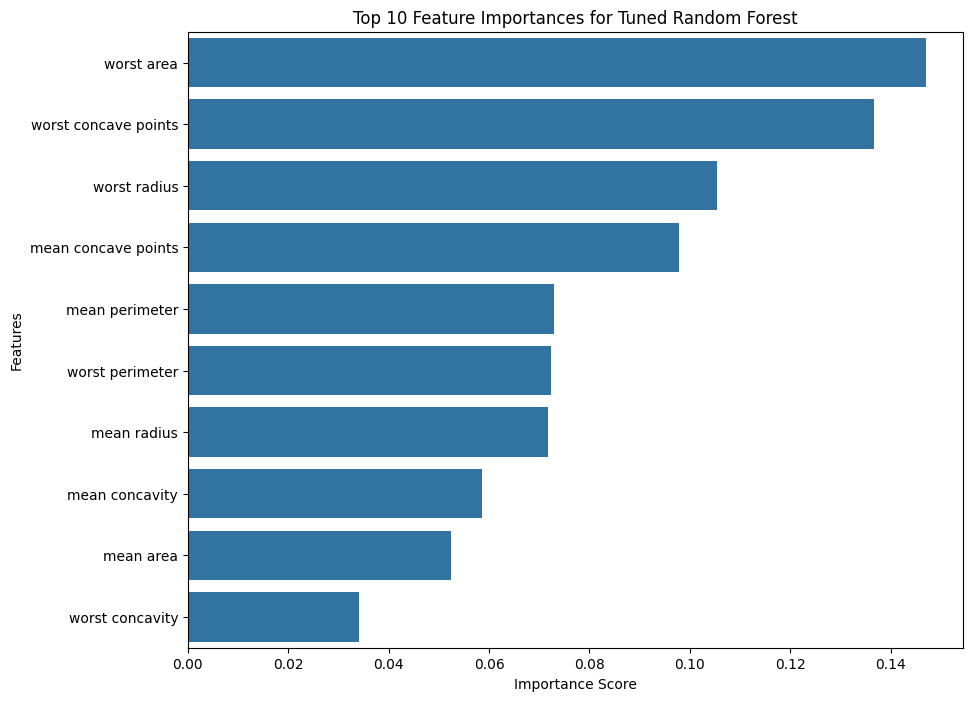

In [11]:
# Create a pipeline for Random Forest
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Define the parameter grid
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=rf_pipeline, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='f1', 
                           n_jobs=-1, 
                           verbose=1)

# Fit the grid search
print("\n--- Running GridSearchCV for Random Forest ---")
grid_search.fit(X_train, y_train)

# Get the best parameters and best score
print(f"\nBest Parameters found by GridSearchCV: {grid_search.best_params_}")
print(f"Best F1-Score from GridSearchCV: {grid_search.best_score_:.4f}")

# Evaluate the best model from GridSearchCV on the test set
grid_best_model = grid_search.best_estimator_
y_pred_grid = grid_best_model.predict(X_test)

print("\n--- Performance of GridSearchCV-tuned Model on Test Set ---")
print(classification_report(y_test, y_pred_grid))

# 1. Confusion Matrix
# This shows us exactly what kind of errors the model is making.
print("\n--- Confusion Matrix for Tuned Random Forest ---")
cm = confusion_matrix(y_test, y_pred_grid)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for Tuned Random Forest")
plt.show()

# 2. Feature Importance
# This shows which features the model found most important for making predictions.
print("\n--- Top 10 Feature Importances ---")
# Extract importances from the 'classifier' step of the pipeline
importances = grid_best_model.named_steps['classifier'].feature_importances_
feature_names = X.columns
forest_importances = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 feature importances
plt.figure(figsize=(10, 8))
sns.barplot(x=forest_importances.head(10), y=forest_importances.head(10).index)
plt.title("Top 10 Feature Importances for Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

# Step 5: Hyperparameter Tuning with RandomizedSearchCV

In [12]:
# Define the parameter distribution for RandomizedSearchCV
# We use distributions for continuous or large discrete spaces
from scipy.stats import randint

param_dist = {
    'classifier__n_estimators': randint(50, 500),
    'classifier__max_depth': randint(5, 50),
    'classifier__min_samples_leaf': randint(1, 10)
}

# Create the RandomizedSearchCV object
# n_iter=50 means it will try 50 random combinations of parameters.
random_search = RandomizedSearchCV(estimator=rf_pipeline,
                                   param_distributions=param_dist,
                                   n_iter=50,
                                   cv=5,
                                   scoring='f1',
                                   n_jobs=-1,
                                   verbose=1,
                                   random_state=42)

# Fit the random search to the data
print("\n--- Running RandomizedSearchCV for Random Forest ---")
random_search.fit(X_train, y_train)

# Get the best parameters and best score
print(f"\nBest Parameters found by RandomizedSearchCV: {random_search.best_params_}")
print(f"Best F1-Score from RandomizedSearchCV: {random_search.best_score_:.4f}")

# Evaluate the best model from RandomizedSearchCV on the test set
random_best_model = random_search.best_estimator_
y_pred_random = random_best_model.predict(X_test)

print("\n--- Performance of RandomizedSearchCV-tuned Model on Test Set ---")
print(classification_report(y_test, y_pred_random))


--- Running RandomizedSearchCV for Random Forest ---
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best Parameters found by RandomizedSearchCV: {'classifier__max_depth': 21, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 99}
Best F1-Score from RandomizedSearchCV: 0.9668

--- Performance of RandomizedSearchCV-tuned Model on Test Set ---
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



# Step 6: Final Analysis and Model Selection



--- FINAL MODEL COMPARISON ---
                           Model  Accuracy  Precision    Recall  F1-Score
0            Logistic Regression  0.982456   0.986111  0.986111  0.986111
1      Support Vector Classifier  0.982456   0.986111  0.986111  0.986111
2            K-Nearest Neighbors  0.956140   0.958904  0.972222  0.965517
3                  Random Forest  0.956140   0.958904  0.972222  0.965517
4        Tuned RF (GridSearchCV)  0.956140   0.958904  0.972222  0.965517
5  Tuned RF (RandomizedSearchCV)  0.956140   0.958904  0.972222  0.965517


C:\Users\vaibh\AppData\Local\Temp\ipykernel_17936\3222534371.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="F1-Score", y="Model", data=final_results_df, palette="viridis")


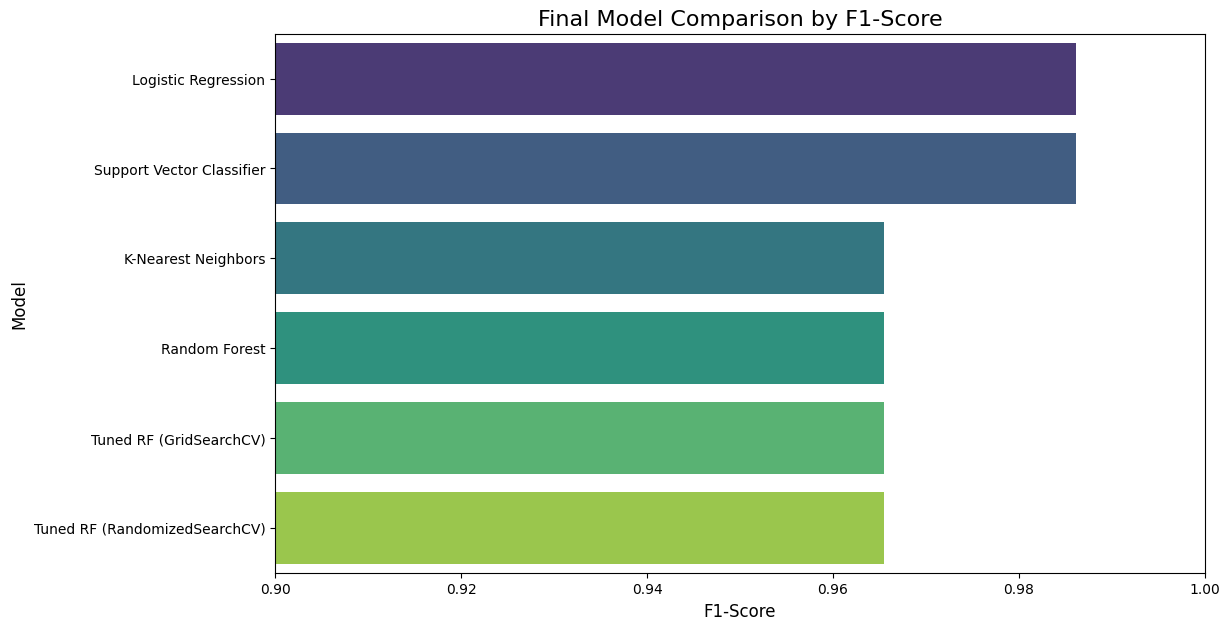

In [14]:
# Prepare results from tuned models
grid_tuned_results = {
    "Model": "Tuned RF (GridSearchCV)",
    "Accuracy": accuracy_score(y_test, y_pred_grid),
    "Precision": precision_score(y_test, y_pred_grid),
    "Recall": recall_score(y_test, y_pred_grid),
    "F1-Score": f1_score(y_test, y_pred_grid)
}

random_tuned_results = {
    "Model": "Tuned RF (RandomizedSearchCV)",
    "Accuracy": accuracy_score(y_test, y_pred_random),
    "Precision": precision_score(y_test, y_pred_random),
    "Recall": recall_score(y_test, y_pred_random),
    "F1-Score": f1_score(y_test, y_pred_random)
}

# Append to the baseline DataFrame
tuned_results_df = pd.DataFrame([grid_tuned_results, random_tuned_results])
final_results_df = pd.concat([baseline_df, tuned_results_df], ignore_index=True)

# Sort by F1-Score for easy comparison
final_results_df = final_results_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print("\n\n--- FINAL MODEL COMPARISON ---")
print(final_results_df)

# Visualize the F1-Scores
plt.figure(figsize=(12, 7))
sns.barplot(x="F1-Score", y="Model", data=final_results_df, palette="viridis")
plt.title("Final Model Comparison by F1-Score", fontsize=16)
plt.xlabel("F1-Score", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.xlim(0.9, 1.0)
plt.show()